# 2. Validation case study: Sailor et al. (2026) traverses

This notebook compares `dc_plume` with the only published air-temperature measurements near operating data centers:

> Sailor, D.J., Samareh Abolhassani, S., Martin, E.P. (2026). Data center waste heat as an emerging urban thermal hazard: first field measurements of neighborhood-scale air temperature impacts. *ASME Journal of Engineering for Sustainable Buildings and Cities* 7(2), 024501. https://doi.org/10.1115/1.4071922 (open access, CC-BY 4.0)

Sailor et al. drove vehicles with aspirated temperature sensors (1.6–2.2 m) around Phoenix-area data centers. Each published value is the difference between the mean temperatures of two averaging areas drawn on a map: downwind minus upwind, or, for NTT PH1, the area nearest the facility minus the farthest one. The repository records three things, and you should cite the paper when you use them:
- the values, in `validation/benchmarks/sailor2026_cases.csv`;
- the facility buildings and averaging areas, digitised from the paper's maps, in `sailor2026_geometry.json`;
- the input rules, fixed before the comparison was run, in `PROTOCOL.md`.

The comparison follows standard dispersion-model evaluation (Chang & Hanna 2004): the model is run for each observed case, and FAC2, fractional bias (FB), NMSE and geometric mean bias (MG) are computed.

In [1]:
import os, sys
# run this notebook from the tutorial/ folder or the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "tutorial" else os.getcwd()
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
import dc_plume as dp
print("dc_plume", "loaded")

dc_plume loaded


In [2]:
import pandas as pd
sys.path.insert(0, os.path.join(ROOT, "validation", "benchmarks"))
import benchmark_sailor2026 as bm          # the benchmark script, used here as a library
%matplotlib inline
bm.CASES[["case", "site", "date_time_local", "IT_MW", "T_C", "U_ms", "wind_from_deg", "stability", "compared", "obs_dT_C"]]

,case,site,date_time_local,IT_MW,T_C,U_ms,wind_from_deg,stability,compared,obs_dT_C
0,a,"CyrusOne PHX1-PHX8, Chandler AZ",2025-06-18 14:25-14:45,169,42.7,2.1,240,B,downwind - upwind,0.8
1,b,"CyrusOne PHX1-PHX8, Chandler AZ",2025-08-08 11:05-11:10,169,39.1,1.5,282,A,downwind - upwind,0.5
2,d,"Digital Realty, 2121 S Price Rd, Chandler AZ",2025-10-25 10:55-11:05,34,24.2,2.1,80,B,downwind - upwind,1.0
3,e,"NTT PH1, 10256 Elliot Rd, Mesa AZ",2025-10-25 10:30-10:40,36,25.0,1.5,150,A,near box T_d3 - far box T_d2,0.9


## The geometry of one case

The facility buildings (grey) are the heat sources, and the model is evaluated along the traverse path inside each averaging area. The arrow shows the direction the wind blows toward.

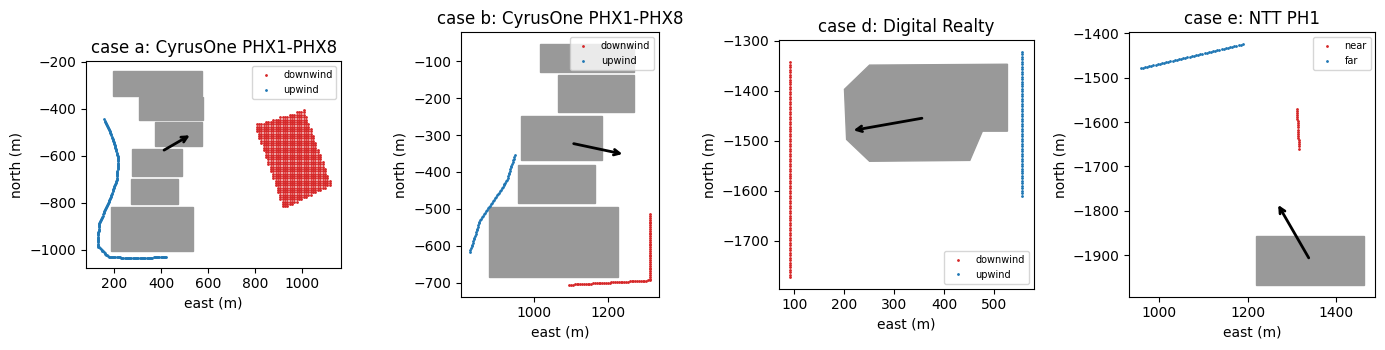

In [3]:
from matplotlib.patches import Polygon as Poly

def show(case, ax):
    g, c, mpp, polys, *_ = bm.setup(case)
    for p in polys:
        ax.add_patch(Poly(p, color="0.6"))
    for key, col in (("downwind", "C3"), ("upwind", "C0"), ("near", "C3"), ("far", "C0")):
        if key in g:
            P = bm.receptors(g[key], mpp)
            ax.plot(P[:, 0], P[:, 1], ".", ms=2, color=col, label=key)
    u, _ = bm.frame(c.wind_from_deg)
    ctr = np.vstack(polys).mean(0)
    ax.annotate("", ctr + 150 * u, ctr, arrowprops=dict(arrowstyle="->", lw=2))
    ax.set(aspect="equal", title=f"case {case}: {c.site.split(',')[0]}", xlabel="east (m)", ylabel="north (m)")
    ax.legend(fontsize=7)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
for case, ax in zip("abde", axs):
    show(case, ax)
fig.tight_layout()

## Model set-up

Inputs not in the paper are set by rule (see `PROTOCOL.md`):
- heat rejected = 1.3 × IT × load fraction (PUE 1.3, as in the paper; load fraction 0.5–1.0, central 0.75), shared between buildings by roof area;
- roof 12 m for single-storey and 20 m for two-storey buildings, with fans 2 m above the roof;
- dry-cooler exhaust 11 K above ambient (reported 8–14 K) at 3 m/s, with 80 kW per fan (50–150 kW);
- stability from the Turner method for the date and time.

In [4]:
for case in "abde":
    print(case, "| observed", bm.CASES.set_index("case").obs_dT_C[case], "C | predicted", round(bm.predict(case), 2), "K")

a | observed 0.8 C | predicted 0.5 K
b | observed 0.5 C | predicted 1.32 K
d | observed 1.0 C | predicted 0.26 K
e | observed 0.9 C | predicted 0.08 K


## All cases, with uncertainty ranges and the merged-plume comparison

In [5]:
rows = []
for c in bm.CASES.itertuples():
    rng = [bm.predict(c.case, l, f) for l in (0.5, 1.0) for f in (50e3, 150e3)]
    rows.append(dict(case=c.case, observed=c.obs_dT_C, predicted=bm.predict(c.case),
                     lo=min(rng), hi=max(rng), merged_plume=bm.predict(c.case, fan_heat=None)))
res = pd.DataFrame(rows).round(3)
res

,case,observed,predicted,lo,hi,merged_plume
0,a,0.8,0.499,0.362,0.643,0.006
1,b,0.5,1.316,0.669,2.020,0.006
2,d,1.0,0.259,0.158,0.406,0.005
3,e,0.9,0.083,0.056,0.124,-0.000


## Performance statistics (Chang & Hanna 2004)

In [6]:
print("fan array       :", {k: round(v, 2) for k, v in bm.metrics(res.observed, res.predicted).items()})
print("one merged plume:", {k: round(v, 2) for k, v in bm.metrics(res.observed, res.merged_plume).items()})
print("mean observed / predicted:", res.observed.mean(), "/", round(res.predicted.mean(), 2))
print("acceptance (Chang & Hanna 2004): FAC2 >= 0.5, |FB| <= 0.3, NMSE <= 1.5, 0.7 <= MG <= 1.3")

fan array       : {'n': 4, 'FAC2': 0.25, 'FB': 0.39, 'NMSE': 1.14, 'MG': 2.25}
one merged plume: {'n': 4, 'FAC2': 0.0, 'FB': 1.98, 'NMSE': 196.65, 'MG': nan}
mean observed / predicted: 0.7999999999999999 / 0.54
acceptance (Chang & Hanna 2004): FAC2 >= 0.5, |FB| <= 0.3, NMSE <= 1.5, 0.7 <= MG <= 1.3


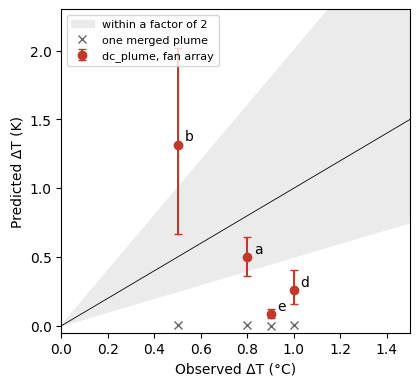

In [7]:
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.fill_between([0, 3], [0, 1.5], [0, 6], color="0.92", label="within a factor of 2")
ax.plot([0, 3], [0, 3], "k-", lw=.6)
ax.errorbar(res.observed, res.predicted, yerr=[res.predicted - res.lo, res.hi - res.predicted],
            fmt="o", color="#c0392b", capsize=3, label="dc_plume, fan array")
ax.plot(res.observed, res.merged_plume, "x", color="0.4", label="one merged plume")
for r in res.itertuples():
    ax.annotate(r.case, (r.observed, r.predicted), xytext=(5, 3), textcoords="offset points")
ax.set(xlim=(0, 1.5), ylim=(-0.05, 2.3), xlabel="Observed ΔT (°C)", ylabel="Predicted ΔT (K)")
ax.legend(fontsize=8, loc="upper left")

## What the comparison shows

- **Mechanism and magnitude.** The fan-array model predicts warming of the observed order, about two-thirds of the observed mean. The fully merged plume, as stack-based plume rise assumes, predicts almost none.
- **Individual cases are not reproduced.** Each observation is a single 5–20 min traverse. Three of the four winds come from airports several kilometres away, and the compared areas differ in land cover. Case e shows how much wind direction matters: with the recorded wind from 150°, the far area lies closer to the plume axis than the near one.

Testing a model case by case needs repeated measurements with on-site wind.

## Adding your own case

1. Add a row to `sailor2026_cases.csv`, with the facility's IT load, floor area, weather and observed difference.
2. Add the buildings and averaging areas to `sailor2026_geometry.json`, in pixels of a map with a scale bar.
3. Run:

```bash
python validation/benchmarks/benchmark_sailor2026.py
```